## 1. Dataset Description

| Informasi | Keterangan |
|---|---|
| Nama Dataset | MBG_Arya |
| Sumber | Berkas lokal proyek `MBG_Arya.csv` |
| URL Kaggle | https://www.kaggle.com/datasets/aryachovapratama/makan-bergizi-gratis-platfrom-yt |
| Jumlah Data | 10.000 baris pada berkas yang diperiksa (akan diverifikasi lagi saat notebook dijalankan) |
| Jumlah Kolom | 3: `text_original`, `clean_text`, `processed_text` |
| Kolom Teks | `text_original` |
| Kolom Label | Tidak tersedia pada dataset |
| Bahasa | Bahasa Indonesia (berdasarkan pemeriksaan sampel teks) |
| Jenis Data | Teks komentar/teks pendek terkait MBG (deskripsi berdasarkan isi sampel) |



In [17]:
# IMPORT LIBRARY
from collections import Counter
from pathlib import Path
import re
import string

import matplotlib.pyplot as plt
import nltk
import pandas as pd
from IPython.display import display
from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.util import bigrams, ngrams, trigrams
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

print("Pandas:", pd.__version__)
print("NLTK:", nltk.__version__)

Pandas: 3.0.6
NLTK: 3.10.3


## 2. Corpus Exploration


In [18]:
#corpus exploration
dataset_candidates = [
    Path.cwd() / "MBG_Arya.csv",
    Path.cwd().parent / "MBG_Arya.csv",
]
dataset_path = next((path for path in dataset_candidates if path.is_file()), None)
if dataset_path is None:
    tried = "\n".join(str(path) for path in dataset_candidates)
    raise FileNotFoundError(
        "MBG_Arya.csv tidak ditemukan. Direktori yang diperiksa:\n" + tried
    )

df = pd.read_csv(dataset_path)
text_column = "text_original"
if text_column not in df.columns:
    raise KeyError(f"Kolom teks '{text_column}' tidak ada. Kolom tersedia: {df.columns.tolist()}")

print("Path dataset:", dataset_path.resolve())
print("Ukuran dataset:", df.shape)
print("Kolom:", df.columns.tolist())
print("Missing values per kolom:")
display(df.isna().sum().rename("missing_values").to_frame())
display(df.head(5))

texts = df[text_column].fillna("").astype(str)
nonempty_texts = texts[texts.str.strip().ne("")]
try:
    raw_sentence_counts = nonempty_texts.apply(
        lambda text: len(sent_tokenize(text, language="english"))
    )
except LookupError as exc:
    raise RuntimeError(
        "Resource Punkt NLTK belum tersedia. Pasang resource NLTK 'punkt' dan 'punkt_tab', lalu jalankan ulang."
    ) from exc

document_word_counts = nonempty_texts.apply(lambda text: len(text.split()))
corpus_statistics = pd.Series({
    "Jumlah dokumen (baris)": len(df),
    "Dokumen teks tidak kosong": len(nonempty_texts),
    "Jumlah kalimat": int(raw_sentence_counts.sum()),
    "Jumlah token/kata (whitespace)": int(document_word_counts.sum()),
    "Jumlah karakter": int(nonempty_texts.str.len().sum()),
    "Rata-rata kata per dokumen": float(document_word_counts.mean()),
    "Dokumen terpendek (kata)": int(document_word_counts.min()),
    "Dokumen terpanjang (kata)": int(document_word_counts.max()),
}, name="Nilai")
display(corpus_statistics.to_frame())

possible_label_columns = ["label", "sentiment", "category", "class"]
label_column = next((col for col in possible_label_columns if col in df.columns), None)
print("Kolom label:", label_column if label_column else "Tidak tersedia")

Path dataset: D:\Semester 5\NLP\modul-1\MBG_Arya.csv
Ukuran dataset: (10000, 3)
Kolom: ['text_original', 'clean_text', 'processed_text']
Missing values per kolom:


,missing_values
text_original,0
clean_text,13
processed_text,197


,text_original,clean_text,processed_text
0,Bang kumis memiliki karakter salesman yg kuat...,bang kumis memiliki karakter salesman yg kuat ...,bang kumis milik karakter salesman yg kuat cir...
1,"Saya nonton krn ada Bang Hensa,dgn Fery Amsari...",saya nonton krn ada bang hensadgn fery amsari,nonton krn bang hensadgn fery amsari
2,"dr awal MBG di kritik rakyat,tp yg kritik di b...",dr awal mbg di kritik rakyattp yg kritik di bl...,dr mbg kritik rakyattp yg kritik blng antek as...
3,"Kalau maling uang rakyat tidak di hukum mati,,...",kalau maling uang rakyat tidak di hukum mati j...,maling uang rakyat hukum mati harap negara maju
4,"Jubirnya kata2nya manis pdhl omdo, dilapangan ...",jubirnya katanya manis pdhl omdo dilapangan ra...,jubirnya manis pdhl omdo lapang rakyat tdk lub...


,Nilai
Jumlah dokumen (baris),1.000000e+04
Dokumen teks tidak kosong,1.000000e+04
Jumlah kalimat,1.457000e+04
Jumlah token/kata (whitespace),1.753160e+05
Jumlah karakter,1.127462e+06
Rata-rata kata per dokumen,1.753160e+01
Dokumen terpendek (kata),1.000000e+00
Dokumen terpanjang (kata),3.620000e+02


Kolom label: Tidak tersedia


## 3. Data Cleaning


In [19]:
#data cleaning
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = text.replace("#", "")
    text = re.sub(r"\d+", " ", text)
    punctuation_without_sentence_marks = string.punctuation.replace(".", "").replace("?", "").replace("!", "")
    text = text.translate(str.maketrans({char: " " for char in punctuation_without_sentence_marks}))
    return re.sub(r"\s+", " ", text).strip()

df["clean_text_pipeline"] = texts.apply(clean_text)
print("Contoh sebelum dan sesudah cleaning:")
display(df[[text_column, "clean_text_pipeline"]].head(5))

Contoh sebelum dan sesudah cleaning:


,text_original,clean_text_pipeline
0,Bang kumis memiliki karakter salesman yg kuat...,bang kumis memiliki karakter salesman yg kuat....
1,"Saya nonton krn ada Bang Hensa,dgn Fery Amsari...",saya nonton krn ada bang hensa dgn fery amsari...
2,"dr awal MBG di kritik rakyat,tp yg kritik di b...",dr awal mbg di kritik rakyat tp yg kritik di b...
3,"Kalau maling uang rakyat tidak di hukum mati,,...",kalau maling uang rakyat tidak di hukum mati j...
4,"Jubirnya kata2nya manis pdhl omdo, dilapangan ...",jubirnya kata nya manis pdhl omdo dilapangan r...


## 4. Sentence Segmentation


In [20]:
#sentence segmentation
try:
    df["sentences"] = df["clean_text_pipeline"].apply(
        lambda text: sent_tokenize(text, language="english") if text else []
    )
except LookupError as exc:
    raise RuntimeError(
        "Resource Punkt NLTK belum tersedia. Pasang resource NLTK 'punkt' dan 'punkt_tab', lalu jalankan ulang."
    ) from exc

print("Contoh kalimat hasil segmentasi:")
for sentence in df.loc[df["sentences"].str.len().gt(0), "sentences"].iloc[0][:5]:
    print("-", sentence)
print("Jumlah kalimat hasil segmentasi:", sum(map(len, df["sentences"])))

Contoh kalimat hasil segmentasi:
- bang kumis memiliki karakter salesman yg kuat.
- ciri khasnya selalu mengulang keunggulan produk yg dijual meski terbukti gagal dng terus menanamkan ke dlm pikiran masyarakat tujuan angan nya.
- persis mencontoh junjunganya
Jumlah kalimat hasil segmentasi: 14698


## 5. Tokenization


In [21]:
# Praktikum 2: Word dan Character Tokenization
# Filter hasil pipeline untuk token kata; tampilan NLTK mentah juga mempertahankan tanda baca.
def tokenize_sentences(sentences):
    return [
        [token for token in word_tokenize(sentence, preserve_line=True) if token.isalpha()]
        for sentence in sentences
    ]

df["sentence_tokens"] = df["sentences"].apply(tokenize_sentences)

sample_text = next((str(text) for text in texts if str(text).strip()), "")
if not sample_text:
    raise ValueError("Tidak ada teks non-kosong untuk demonstrasi tokenisasi.")
sample_sentence = next(
    (sentence for sentence_list in df["sentences"] for sentence in sentence_list),
    sample_text,
)
print("Contoh sentence segmentation:", df.loc[df["sentences"].str.len().gt(0), "sentences"].iloc[0][:3])
print("split():", sample_sentence.split())
print("NLTK word_tokenize():", word_tokenize(sample_sentence, preserve_line=True))
print("Token kata untuk pipeline:", tokenize_sentences([sample_sentence])[0])
print("Character tokens (50 karakter pertama):", list(sample_text[:50]))

Contoh sentence segmentation: ['bang kumis memiliki karakter salesman yg kuat.', 'ciri khasnya selalu mengulang keunggulan produk yg dijual meski terbukti gagal dng terus menanamkan ke dlm pikiran masyarakat tujuan angan nya.', 'persis mencontoh junjunganya']
split(): ['bang', 'kumis', 'memiliki', 'karakter', 'salesman', 'yg', 'kuat.']
NLTK word_tokenize(): ['bang', 'kumis', 'memiliki', 'karakter', 'salesman', 'yg', 'kuat', '.']
Token kata untuk pipeline: ['bang', 'kumis', 'memiliki', 'karakter', 'salesman', 'yg', 'kuat']
Character tokens (50 karakter pertama): ['B', 'a', 'n', 'g', ' ', ' ', 'k', 'u', 'm', 'i', 's', ' ', 'm', 'e', 'm', 'i', 'l', 'i', 'k', 'i', ' ', 'k', 'a', 'r', 'a', 'k', 't', 'e', 'r', ' ', 's', 'a', 'l', 'e', 's', 'm', 'a', 'n', ' ', 'y', 'g', ' ', 'k', 'u', 'a', 't', '.', ' ', 'C', 'i']


## 6. Normalization


In [22]:
#normalization
normalization_map = {
    "yg": "yang",
    "dgn": "dengan",
    "dlm": "dalam",
    "dng": "dengan",
    "krn": "karena",
    "gak": "tidak",
    "ga": "tidak",
    "gk": "tidak",
    "nggak": "tidak",
}

def normalize_tokens(sentence_token_lists):
    return [
        [normalization_map.get(token, token) for token in sentence]
        for sentence in sentence_token_lists
    ]

df["normalized_tokens"] = df["sentence_tokens"].apply(normalize_tokens)
print("Contoh token setelah normalisasi:")
print(df.loc[df["normalized_tokens"].str.len().gt(0), "normalized_tokens"].iloc[0][:3])

Contoh token setelah normalisasi:
[['bang', 'kumis', 'memiliki', 'karakter', 'salesman', 'yang', 'kuat'], ['ciri', 'khasnya', 'selalu', 'mengulang', 'keunggulan', 'produk', 'yang', 'dijual', 'meski', 'terbukti', 'gagal', 'dengan', 'terus', 'menanamkan', 'ke', 'dalam', 'pikiran', 'masyarakat', 'tujuan', 'angan', 'nya'], ['persis', 'mencontoh', 'junjunganya']]


## 7. Stopword Removal


In [23]:
#stopword removal
try:
    stop_words = set(stopwords.words("indonesian"))
except LookupError as exc:
    raise RuntimeError(
        "Daftar stopword NLTK belum tersedia. Pasang resource NLTK 'stopwords', lalu jalankan ulang."
    ) from exc

def remove_stopwords(sentence_token_lists):
    return [
        [token for token in sentence if token not in stop_words]
        for sentence in sentence_token_lists
    ]

df["tokens_without_stopwords"] = df["normalized_tokens"].apply(remove_stopwords)
print("Contoh setelah stopword removal:")
print(df.loc[df["tokens_without_stopwords"].str.len().gt(0), "tokens_without_stopwords"].iloc[0][:3])

Contoh setelah stopword removal:
[['bang', 'kumis', 'memiliki', 'karakter', 'salesman', 'kuat'], ['ciri', 'khasnya', 'mengulang', 'keunggulan', 'produk', 'dijual', 'terbukti', 'gagal', 'menanamkan', 'pikiran', 'masyarakat', 'tujuan', 'angan', 'nya'], ['persis', 'mencontoh', 'junjunganya']]


## 8. Stemming


In [24]:
#stemming
stemmer = StemmerFactory().create_stemmer()

# Stem setiap kata unik sekali dan tampilkan progres untuk korpus besar.
unique_tokens = sorted({
    token
    for document in df["tokens_without_stopwords"]
    for sentence in document
    for token in sentence
})
print(f"Jumlah kata unik yang akan di-stem: {len(unique_tokens):,}")
stemmed_vocabulary = {}
for index, token in enumerate(unique_tokens, start=1):
    stemmed_vocabulary[token] = stemmer.stem(token)
    if index % 1000 == 0:
        print(f"Stemming: {index:,}/{len(unique_tokens):,} kata unik")

def stem_sentence_tokens(sentence_token_lists):
    return [
        [stemmed_vocabulary[token] for token in sentence if token]
        for sentence in sentence_token_lists
    ]

df["stemmed_tokens"] = df["tokens_without_stopwords"].apply(stem_sentence_tokens)
model_sentences = [
    sentence
    for document in df["stemmed_tokens"]
    for sentence in document
    if sentence
]
model_tokens = [token for sentence in model_sentences for token in sentence]
print("Contoh hasil stemming:")
print(df.loc[df["stemmed_tokens"].str.len().gt(0), "stemmed_tokens"].iloc[0][:3])
print("Jumlah token setelah preprocessing:", len(model_tokens))

Jumlah kata unik yang akan di-stem: 15,960
Stemming: 1,000/15,960 kata unik
Stemming: 2,000/15,960 kata unik
Stemming: 3,000/15,960 kata unik
Stemming: 4,000/15,960 kata unik
Stemming: 5,000/15,960 kata unik
Stemming: 6,000/15,960 kata unik
Stemming: 7,000/15,960 kata unik
Stemming: 8,000/15,960 kata unik
Stemming: 9,000/15,960 kata unik
Stemming: 10,000/15,960 kata unik
Stemming: 11,000/15,960 kata unik
Stemming: 12,000/15,960 kata unik
Stemming: 13,000/15,960 kata unik
Stemming: 14,000/15,960 kata unik
Stemming: 15,000/15,960 kata unik
Contoh hasil stemming:
[['bang', 'kumis', 'milik', 'karakter', 'salesman', 'kuat'], ['ciri', 'khas', 'ulang', 'unggul', 'produk', 'jual', 'bukti', 'gagal', 'tanam', 'pikir', 'masyarakat', 'tuju', 'angan', 'nya'], ['persis', 'contoh', 'junjunganya']]
Jumlah token setelah preprocessing: 108588


## 9. POS Tagging


In [25]:
# Praktikum 4: POS Tagging dengan Stanza
import stanza

stanza.download("id")
task_nlp = stanza.Pipeline(
    lang="id",
    processors="tokenize,pos,lemma,depparse",
    verbose=False,
)

linguistic_samples = (
    df[text_column]
    .dropna()
    .astype(str)
    .str.strip()
)
linguistic_samples = linguistic_samples[linguistic_samples.ne("")].drop_duplicates().head(3).tolist()
if not linguistic_samples:
    raise ValueError("Tidak ada teks non-kosong untuk analisis linguistik.")

parsed_samples = [task_nlp(text) for text in linguistic_samples]
pos_rows = [
    {
        "Kalimat": original_text,
        "Token": word.text,
        "POS": word.upos,
        "POS Tag": word.xpos,
        "Lemma": word.lemma,
    }
    for original_text, doc in zip(linguistic_samples, parsed_samples)
    for sentence in doc.sentences
    for word in sentence.words
]
pos_results = pd.DataFrame(pos_rows)
display(pos_results)

2026-10-24 13:52:53 INFO: Downloaded file to C:\Users\ASUS\AppData\Local\StanfordNLP\stanza\Cache\1.15.0\resources\resources.json
2026-10-24 13:52:53 INFO: Downloading default packages for language: id (Indonesian) ...
2026-10-24 13:52:56 INFO: File exists: C:\Users\ASUS\AppData\Local\StanfordNLP\stanza\Cache\1.15.0\resources\id\default.zip
2026-10-24 13:53:00 INFO: Finished downloading models and saved to C:\Users\ASUS\AppData\Local\StanfordNLP\stanza\Cache\1.15.0\resources


,Kalimat,Token,POS,POS Tag,Lemma
0,Bang kumis memiliki karakter salesman yg kuat...,Bang,PROPN,F--,bang
1,Bang kumis memiliki karakter salesman yg kuat...,kumis,NOUN,X--,kumis
2,Bang kumis memiliki karakter salesman yg kuat...,memiliki,VERB,VSA,milik
3,Bang kumis memiliki karakter salesman yg kuat...,karakter,NOUN,NSD,karakter
4,Bang kumis memiliki karakter salesman yg kuat...,salesman,NOUN,X--,salesman
...,...,...,...,...,...
72,"dr awal MBG di kritik rakyat,tp yg kritik di b...",korupsi,NOUN,NSD,korupsi
73,"dr awal MBG di kritik rakyat,tp yg kritik di b...",!,PUNCT,Z--,!
74,"dr awal MBG di kritik rakyat,tp yg kritik di b...",!,PUNCT,Z--,!
75,"dr awal MBG di kritik rakyat,tp yg kritik di b...",!,PUNCT,Z--,!


## 10. Dependency Parsing


In [26]:
# Praktikum 4: Dependency Parsing dengan Stanza
dependency_rows = []
for original_text, doc in zip(linguistic_samples, parsed_samples):
    for sentence in doc.sentences:
        words_by_id = {word.id: word.text for word in sentence.words}
        for word in sentence.words:
            dependency_rows.append({
                "Kalimat": original_text,
                "Token": word.text,
                "Dependency": word.deprel,
                "Head": "ROOT" if word.head == 0 else words_by_id.get(word.head, "Tidak diketahui"),
            })

dependency_results = pd.DataFrame(dependency_rows)
display(dependency_results)

,Kalimat,Token,Dependency,Head
0,Bang kumis memiliki karakter salesman yg kuat...,Bang,nsubj,memiliki
1,Bang kumis memiliki karakter salesman yg kuat...,kumis,compound,Bang
2,Bang kumis memiliki karakter salesman yg kuat...,memiliki,root,ROOT
3,Bang kumis memiliki karakter salesman yg kuat...,karakter,obj,memiliki
4,Bang kumis memiliki karakter salesman yg kuat...,salesman,compound,karakter
...,...,...,...,...
72,"dr awal MBG di kritik rakyat,tp yg kritik di b...",korupsi,compound,duit
73,"dr awal MBG di kritik rakyat,tp yg kritik di b...",!,punct,suka
74,"dr awal MBG di kritik rakyat,tp yg kritik di b...",!,punct,dr
75,"dr awal MBG di kritik rakyat,tp yg kritik di b...",!,punct,muaaaaaaaaak


## Analisis Linguistik: Tugas Praktikum 4

Analisis 10 kalimat unik dari dataset dengan tokenisasi, POS tagging, dan dependency parsing. Hasil per kalimat ditampilkan dalam tabel, dengan satu sel diagram untuk setiap kalimat.

In [27]:
# ==========================================
# PERSIAPAN DATA 10 KALIMAT UNIK (PRAKTIKUM 4)
# ==========================================
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from IPython.display import display
from matplotlib.path import Path as PlotPath
from matplotlib.patches import FancyArrowPatch

# Gunakan DataFrame MBG_Arya.csv yang sudah dimuat di awal pipeline.
# Fallback ini memungkinkan sel dijalankan sendiri setelah kernel di-reset.
if "df" not in globals() or "text_original" not in df.columns:
    dataset_candidates = [
        Path.cwd() / "MBG_Arya.csv",
        Path.cwd().parent / "MBG_Arya.csv",
    ]
    dataset_path = next((candidate for candidate in dataset_candidates if candidate.is_file()), None)
    if dataset_path is None:
        raise FileNotFoundError("MBG_Arya.csv tidak ditemukan di folder proyek atau folder induknya.")
    df = pd.read_csv(dataset_path)

if "task_nlp" not in globals():
    import stanza
    stanza.download("id")
    task_nlp = stanza.Pipeline(
        lang="id",
        processors="tokenize,pos,lemma,depparse",
        verbose=False,
    )

analysis_column = "text_original"
analysis_candidates = df[analysis_column].dropna().astype(str).str.strip()
analysis_candidates = analysis_candidates[analysis_candidates.ne("")]
analysis_candidates = analysis_candidates.loc[
    ~analysis_candidates.map(lambda text: " ".join(text.casefold().split())).duplicated()
]
if len(analysis_candidates) < 10:
    raise ValueError(
        f"Dibutuhkan minimal 10 teks unik, tetapi hanya tersedia {len(analysis_candidates)}."
    )

sampled_texts = analysis_candidates.sample(frac=1, random_state=42).tolist()
selected_sentences = []
seen_sentences = set()
for text in sampled_texts:
    parsed_doc = task_nlp(text)
    for parsed_sentence in parsed_doc.sentences:
        if not parsed_sentence.words:
            continue
        sentence_key = " ".join(parsed_sentence.text.casefold().split())
        if sentence_key in seen_sentences:
            continue
        seen_sentences.add(sentence_key)
        selected_sentences.append(parsed_sentence)
        if len(selected_sentences) == 10:
            break
    if len(selected_sentences) == 10:
        break

if len(selected_sentences) < 10:
    raise ValueError(
        f"Hanya ditemukan {len(selected_sentences)} kalimat unik yang dapat dianalisis."
    )
print(f"Siap menganalisis {len(selected_sentences)} kalimat unik dari {dataset_path.name if 'dataset_path' in globals() else 'MBG_Arya.csv'}.")
for sentence_number, parsed_sentence in enumerate(selected_sentences, start=1):
    print(f"{sentence_number}. {parsed_sentence.text}")

Siap menganalisis 10 kalimat unik dari MBG_Arya.csv.
1. Bang, sy on progres bangun dapur MBG. Mau lah dapur sy nanti jadi project bareng.
2. bang Raymond pasti tau, mau dibahas sampe kapan pun gak bakal bener negara ni.
3. alasannya karena sejak awal populasi sudah tidak merata, dsni monopoli kekuasaan mereka.
4. 1 pulau Kalimantan = 20jt org, 1 pulau sulawesi = 20 jt orang, 1 pulau papua =20 jt orang, tapi 1 provinsi Jawa barat saja 50 jt orang.
5. jadi gak adil dong?
6. ya emang...ini ilusi demokrasi kita yg gak akan berani dibahas oleh konten2 kreator politik.
7. monopoli kekuasaan akan berputar disitu2 saja, menteri2 boneka, proyek bagi2 kue, janji 19 jt lapangan voli, mw dibahas jg cman jadi paradox yg akan selalu terulang kembali sampe kita ubanan, punya cucu, terus masuk liang lahat.
8. Kabari kalau hukuman mati buat koruptor sudah berlaku
9. kacung2 nya saja ini
10. Stop dan stop stop stop stop stop MBG program beracun yang sudah merenggut puluh ribu nyawa manusia astaghfirulla

In [28]:
# ==========================================
# 11.2 TABEL HASIL ANALISIS
# ==========================================
# Satu baris per kalimat agar tabel tidak tampak seperti mengulang kalimat.
# Catatan analisis manual berdasarkan hasil yang sudah diperiksa.
# Beberapa label (mis. PROPN/PRON atau DET/PRON) tetap bergantung pada konteks.
manual_error_notes = {
    1: (
        '"sy" merupakan singkatan informal "saya" dan seharusnya PRON. '
        'Periksa kembali label "Bang" sesuai konteks sapaan/nama. '
        'Relasi koma sebagai punct perlu mengarah ke token yang tepat, bukan menjadikan "sy" sebagai punct.'
    ),
    2: (
        'Periksa label "bang" yang menjadi PROPN; huruf kecil tidak otomatis menentukan kelas katanya. '
        'Relasi flat:name pada "bang Raymond" perlu ditinjau arah head-nya; jika "bang" sapaan, analisis flat/appos dapat berbeda.'
    ),
    3: (
        'Pada frasa "sejak awal", "awal" lebih sesuai dianalisis sebagai nomina (NOUN), bukan adjective (ADJ). '
        'Pemisahan "alasan" dan "nya" sudah sesuai dengan hasil yang dilaporkan.'
    ),
    4: (
        'Token "20jt" sebaiknya diperiksa karena angka dan singkatan "jt" dapat perlu dipisahkan menjadi NUM + NOUN. '
        'Label simbol "=" juga perlu dibandingkan dengan konvensi anotasi yang digunakan.'
    ),
    5: (
        '"dong" berfungsi sebagai partikel penegas (PART; bergantung panduan anotasi). '
        'Label/relasi "adil" dan "jadi" perlu ditinjau berdasarkan fungsi dalam konteks; '
        'jangan simpulkan root hanya dari kelas katanya.'
    ),
    6: (
        '"emang" adalah bentuk informal "memang"; dalam konteks ini lebih mungkin ADV atau PART daripada VERB.'
    ),
    7: (
        '"disitu2" adalah bentuk informal/tidak baku dan tokennya perlu ditinjau. '
        'Normalisasi menjadi "di situ-situ" atau bentuk sesuai konteks dapat membantu; '
        'jangan langsung menetapkan POS tanpa melihat kalimat lengkap.'
    ),
    8: (
        '"Kabari" tampaknya kata kerja imperatif (VERB), bukan PROPN. Kapitalisasi di awal kalimat '
        'kemungkinan membuat model salah mengira sebagai nama diri.'
    ),
    9: (
        '"ini" dapat berlabel DET jika menerangkan nomina atau PRON jika berdiri sendiri sebagai penunjuk; '
        'periksa fungsi sintaksisnya dalam kalimat.'
    ),
    10: (
        '"Stop/stop" tampaknya dipakai sebagai perintah atau interjeksi, bukan PROPN/NOUN. '
        'Tentukan label yang konsisten menurut konteks dan panduan anotasi.'
    ),
}
analysis_rows = []
for sentence_number, parsed_sentence in enumerate(selected_sentences, start=1):
    words_by_id = {word.id: word.text for word in parsed_sentence.words}
    tokens = [word.text for word in parsed_sentence.words]
    pos_tags = [word.upos for word in parsed_sentence.words]
    dependencies = [
        f"{word.deprel} -> {'ROOT' if word.head == 0 else words_by_id.get(word.head, 'Tidak diketahui')}"
        for word in parsed_sentence.words
    ]
    analysis_rows.append({
        "No.": sentence_number,
        "Kalimat": parsed_sentence.text,
        "Token": " | ".join(tokens),
        "POS": " | ".join(pos_tags),
        "Dependency": " | ".join(dependencies),
        "Kesalahan?": manual_error_notes.get(
            sentence_number, "Belum ditinjau manual; cek hasil parser terhadap konteks kalimat"
        ),
    })

analysis_table = pd.DataFrame(analysis_rows)
assert analysis_table["Kalimat"].nunique() == len(selected_sentences), (
    "Kalimat yang dipilih tidak unik. Jalankan ulang sel persiapan."
)
display(analysis_table)


,No.,Kalimat,Token,POS,Dependency,Kesalahan?
0,1,"Bang, sy on progres bangun dapur MBG. Mau lah ...","Bang | , | sy | on | progres | bangun | dapur ...",PROPN | PUNCT | PROPN | PROPN | NOUN | VERB | ...,nsubj -> bangun | punct -> sy | flat:name -> B...,"""sy"" merupakan singkatan informal ""saya"" dan s..."
1,2,"bang Raymond pasti tau, mau dibahas sampe kapa...","bang | Raymond | pasti | tau | , | mau | dibah...",PROPN | PROPN | ADV | VERB | PUNCT | AUX | VER...,nsubj -> tau | flat:name -> bang | advmod -> t...,"Periksa label ""bang"" yang menjadi PROPN; huruf..."
2,3,alasannya karena sejak awal populasi sudah tid...,alasan | nya | karena | sejak | awal | populas...,NOUN | PRON | SCONJ | ADP | ADJ | NOUN | AUX |...,root -> ROOT | nmod:poss -> alasan | mark -> m...,"Pada frasa ""sejak awal"", ""awal"" lebih sesuai d..."
3,4,"1 pulau Kalimantan = 20jt org, 1 pulau sulawes...","1 | pulau | Kalimantan | = | 20jt | org | , | ...",NUM | NOUN | PROPN | SYM | NOUN | NOUN | PUNCT...,nummod -> pulau | root -> ROOT | nmod -> pulau...,"Token ""20jt"" sebaiknya diperiksa karena angka ..."
4,5,jadi gak adil dong?,jadi | gak | adil | dong | ?,VERB | PART | ADJ | NOUN | PUNCT,root -> ROOT | advmod -> adil | amod -> jadi |...,"""dong"" berfungsi sebagai partikel penegas (PAR..."
5,6,ya emang...ini ilusi demokrasi kita yg gak aka...,ya | emang | . | ..ini | ilusi | demokrasi | k...,PART | VERB | PUNCT | PUNCT | NOUN | NOUN | PR...,advmod -> emang | root -> ROOT | punct -> eman...,"""emang"" adalah bentuk informal ""memang""; dalam..."
6,7,"monopoli kekuasaan akan berputar disitu2 saja,...",monopoli | kekuasaan | akan | berputar | disit...,NOUN | NOUN | AUX | VERB | NOUN | ADV | PUNCT ...,nsubj -> berputar | compound -> monopoli | aux...,"""disitu2"" adalah bentuk informal/tidak baku da..."
7,8,Kabari kalau hukuman mati buat koruptor sudah ...,Kabari | kalau | hukuman | mati | buat | korup...,PROPN | SCONJ | NOUN | ADJ | ADP | NOUN | AUX ...,nsubj -> berlaku | mark -> berlaku | nsubj -> ...,"""Kabari"" tampaknya kata kerja imperatif (VERB)..."
8,9,kacung2 nya saja ini,kacung2 | nya | saja | ini,NOUN | PRON | ADV | DET,root -> ROOT | nmod:poss -> kacung2 | advmod -...,"""ini"" dapat berlabel DET jika menerangkan nomi..."
9,10,Stop dan stop stop stop stop stop MBG program ...,Stop | dan | stop | stop | stop | stop | stop ...,PROPN | CCONJ | NOUN | NOUN | NOUN | NOUN | NO...,root -> ROOT | cc -> stop | conj -> Stop | com...,"""Stop/stop"" tampaknya dipakai sebagai perintah..."


In [29]:
# ==========================================
# 11.3 FUNGSI VISUALISASI DEPENDENCY TREE
# ==========================================
def plot_dependency_tree(parsed_sentence, sentence_number):
    words = parsed_sentence.words
    positions = {word.id: index for index, word in enumerate(words)}
    figure_width = max(9, min(22, len(words) * 0.75))
    fig, ax = plt.subplots(figsize=(figure_width, 4.8))

    for index, word in enumerate(words):
        ax.text(
            index, 0, word.text, ha="center", va="center", fontsize=10,
            bbox={"boxstyle": "round,pad=0.3", "facecolor": "#eaf2f8", "edgecolor": "#5d6d7e"},
        )
        ax.text(index, -0.42, word.upos, ha="center", va="center", fontsize=8, color="#34495e")
        if word.head == 0:
            ax.text(index, 0.62, "ROOT", ha="center", va="bottom", fontsize=8, color="#922b21")
            continue

        head_index = positions.get(word.head)
        if head_index is None:
            continue
        height = 0.85 + abs(index - head_index) * 0.22
        curve = PlotPath(
            [(head_index, 0.16), (head_index, height), (index, height), (index, 0.16)],
            [PlotPath.MOVETO, PlotPath.CURVE4, PlotPath.CURVE4, PlotPath.CURVE4],
        )
        ax.add_patch(FancyArrowPatch(
            path=curve, arrowstyle="-|>", mutation_scale=9, linewidth=1,
            color="#2874a6", shrinkA=4, shrinkB=4,
        ))
        ax.text(
            (head_index + index) / 2, height + 0.05, word.deprel,
            ha="center", va="bottom", fontsize=8, color="#1b4f72",
        )

    ax.set_title(f"Dependency Tree Kalimat {sentence_number}: {parsed_sentence.text}", fontsize=10)
    ax.set_xlim(-0.6, len(words) - 0.4)
    ax.set_ylim(-0.75, max(1.5, len(words) * 0.22 + 1.2))
    ax.axis("off")
    fig.tight_layout()
    display(fig)
    plt.close(fig)


Kalimat 1: Bang, sy on progres bangun dapur MBG. Mau lah dapur sy nanti jadi project bareng.


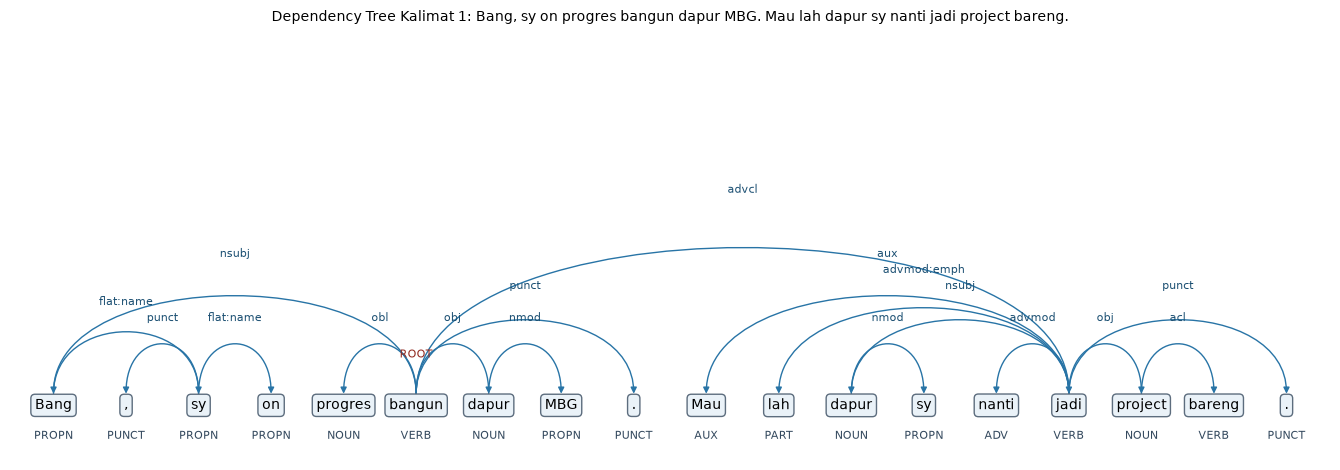

In [30]:
# ==========================================
# DEPENDENCY TREE KALIMAT 1
# ==========================================
print("Kalimat 1:", selected_sentences[0].text)
plot_dependency_tree(selected_sentences[0], 1)


Kalimat 2: bang Raymond pasti tau, mau dibahas sampe kapan pun gak bakal bener negara ni.


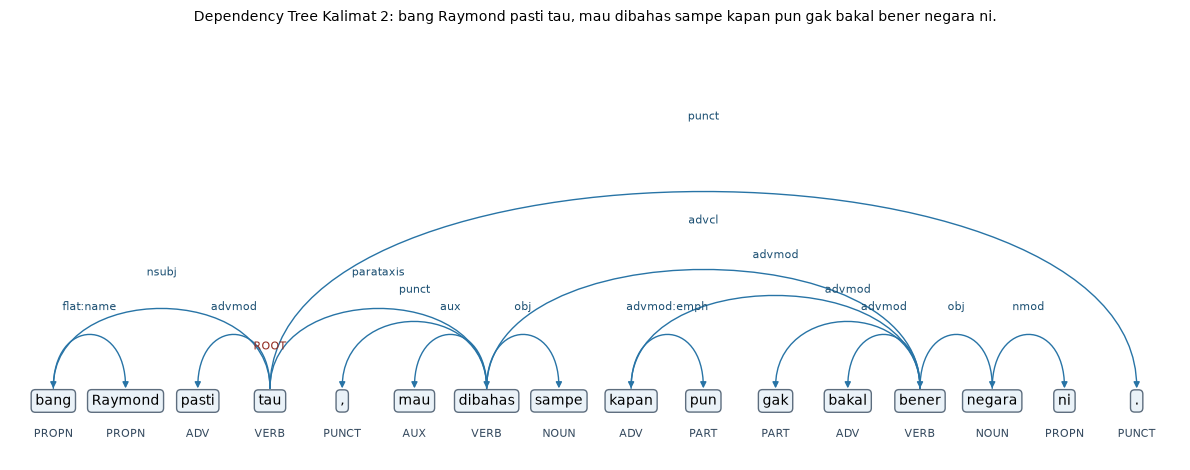

In [31]:
# ==========================================
# DEPENDENCY TREE KALIMAT 2
# ==========================================
print("Kalimat 2:", selected_sentences[1].text)
plot_dependency_tree(selected_sentences[1], 2)


Kalimat 3: alasannya karena sejak awal populasi sudah tidak merata, dsni monopoli kekuasaan mereka.


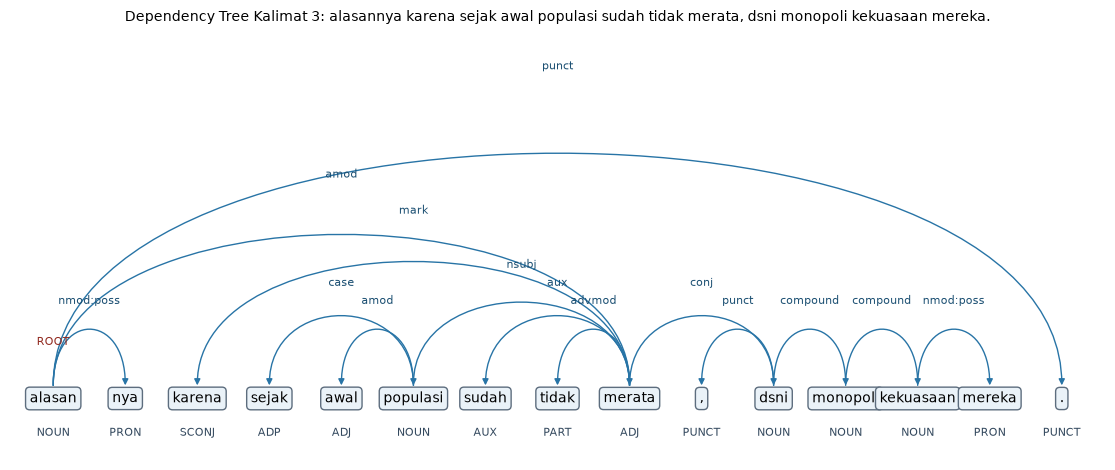

In [32]:
# ==========================================
# DEPENDENCY TREE KALIMAT 3
# ==========================================
print("Kalimat 3:", selected_sentences[2].text)
plot_dependency_tree(selected_sentences[2], 3)


Kalimat 4: 1 pulau Kalimantan = 20jt org, 1 pulau sulawesi = 20 jt orang, 1 pulau papua =20 jt orang, tapi 1 provinsi Jawa barat saja 50 jt orang.


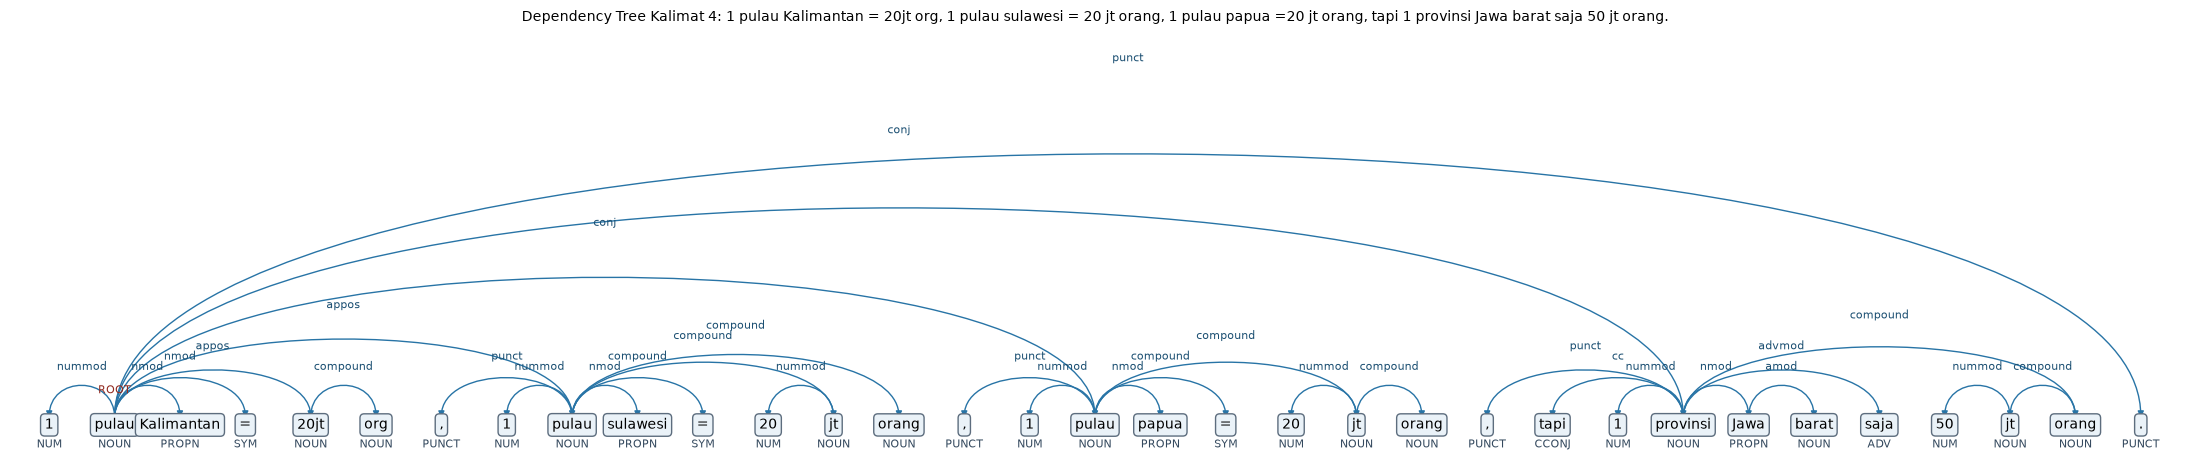

In [33]:
# ==========================================
# DEPENDENCY TREE KALIMAT 4
# ==========================================
print("Kalimat 4:", selected_sentences[3].text)
plot_dependency_tree(selected_sentences[3], 4)


Kalimat 5: jadi gak adil dong?


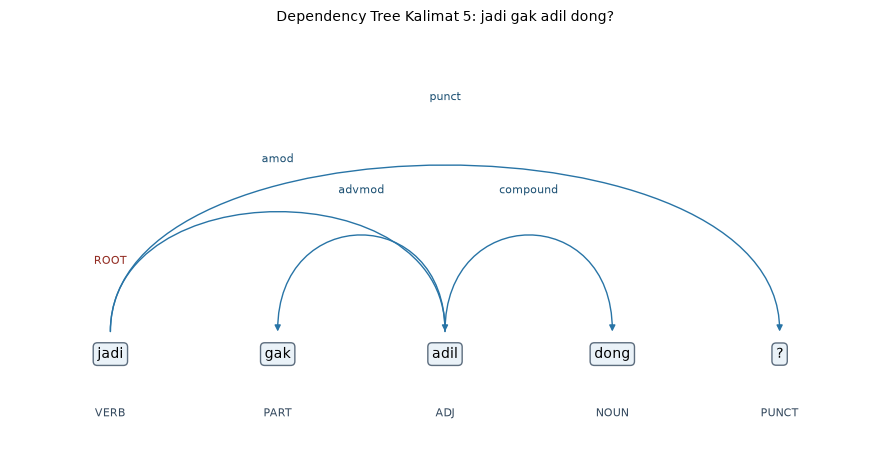

In [34]:
# ==========================================
# DEPENDENCY TREE KALIMAT 5
# ==========================================
print("Kalimat 5:", selected_sentences[4].text)
plot_dependency_tree(selected_sentences[4], 5)


Kalimat 6: ya emang...ini ilusi demokrasi kita yg gak akan berani dibahas oleh konten2 kreator politik.


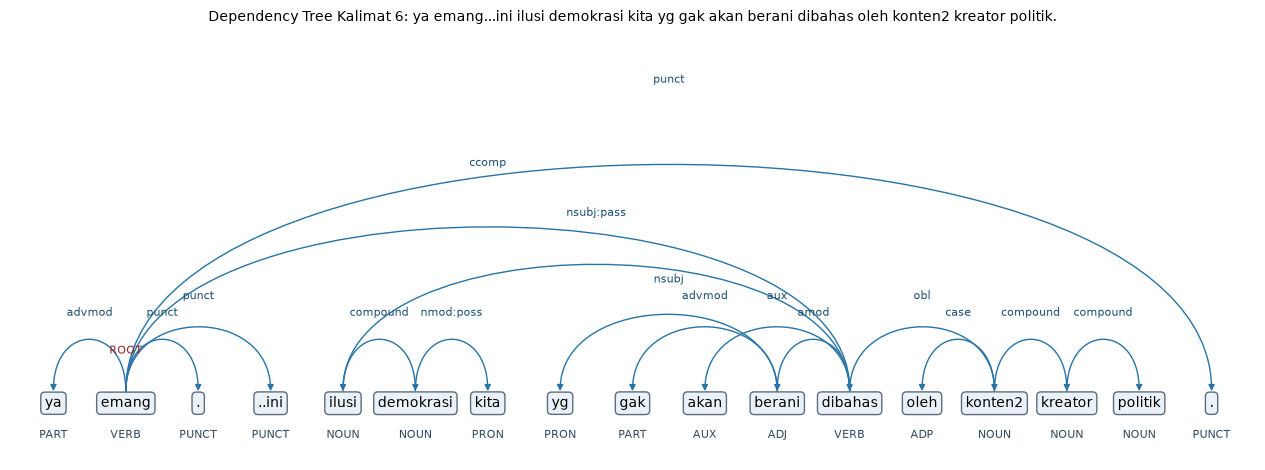

In [35]:
# ==========================================
# DEPENDENCY TREE KALIMAT 6
# ==========================================
print("Kalimat 6:", selected_sentences[5].text)
plot_dependency_tree(selected_sentences[5], 6)


Kalimat 7: monopoli kekuasaan akan berputar disitu2 saja, menteri2 boneka, proyek bagi2 kue, janji 19 jt lapangan voli, mw dibahas jg cman jadi paradox yg akan selalu terulang kembali sampe kita ubanan, punya cucu, terus masuk liang lahat.


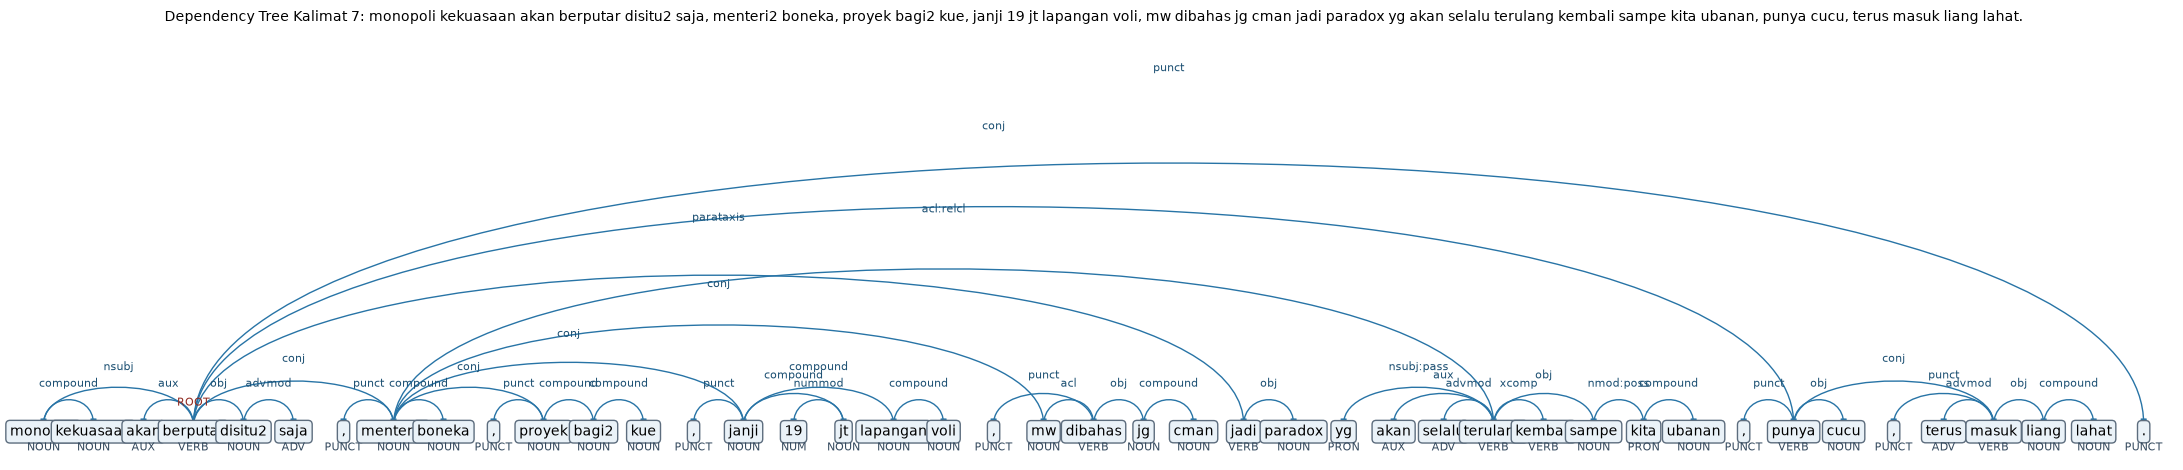

In [36]:
# ==========================================
# DEPENDENCY TREE KALIMAT 7
# ==========================================
print("Kalimat 7:", selected_sentences[6].text)
plot_dependency_tree(selected_sentences[6], 7)


Kalimat 8: Kabari kalau hukuman mati buat koruptor sudah berlaku


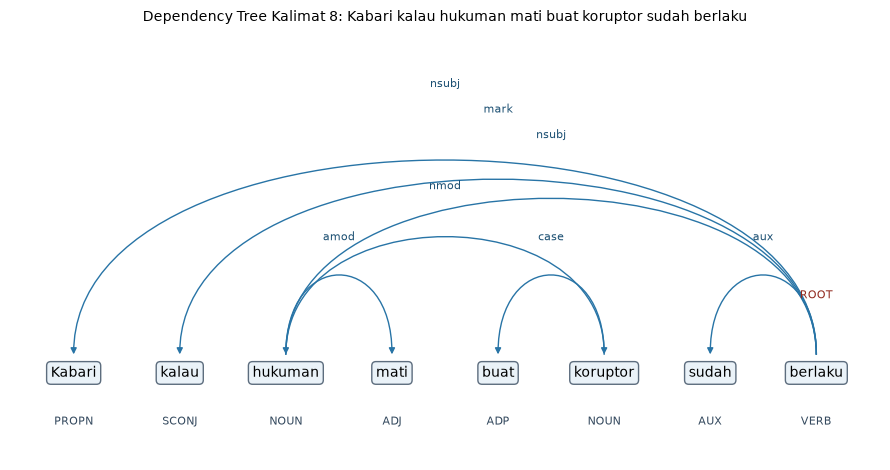

In [37]:
# ==========================================
# DEPENDENCY TREE KALIMAT 8
# ==========================================
print("Kalimat 8:", selected_sentences[7].text)
plot_dependency_tree(selected_sentences[7], 8)


Kalimat 9: kacung2 nya saja ini


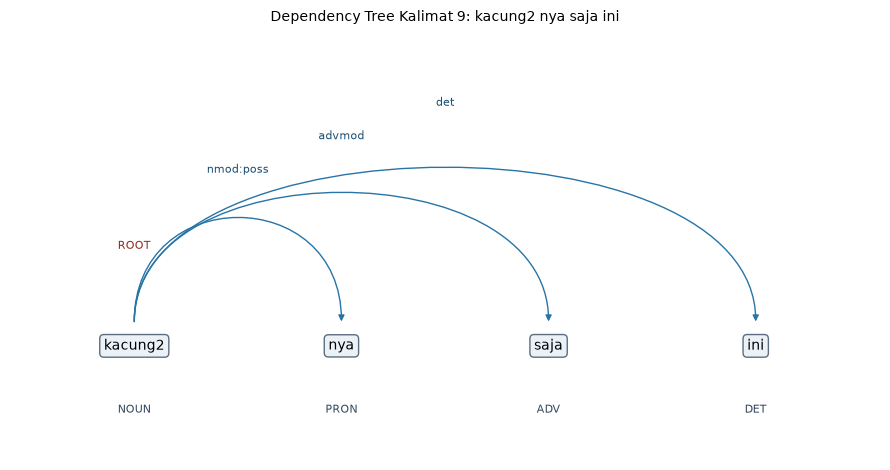

In [38]:
# ==========================================
# DEPENDENCY TREE KALIMAT 9
# ==========================================
print("Kalimat 9:", selected_sentences[8].text)
plot_dependency_tree(selected_sentences[8], 9)


Kalimat 10: Stop dan stop stop stop stop stop MBG program beracun yang sudah merenggut puluh ribu nyawa manusia astaghfirullah adzim


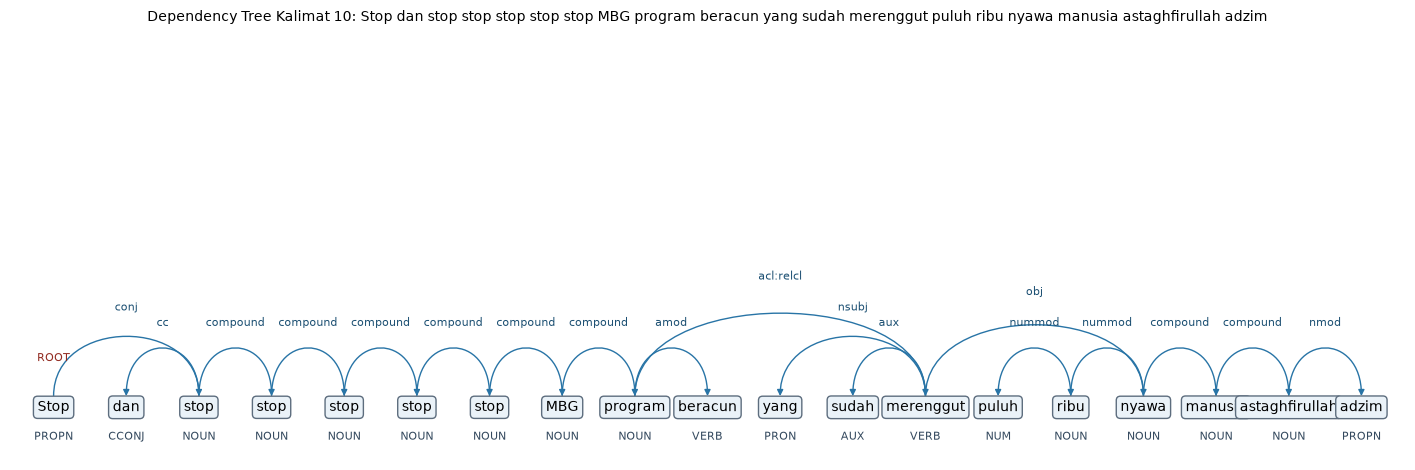

In [39]:
# ==========================================
# DEPENDENCY TREE KALIMAT 10
# ==========================================
print("Kalimat 10:", selected_sentences[9].text)
plot_dependency_tree(selected_sentences[9], 10)


## 11. N-Gram


In [40]:
#N-gram
unigram_frequency = Counter(model_tokens)
bigram_frequency = Counter(
    gram for sentence in model_sentences for gram in bigrams(sentence)
)
trigram_frequency = Counter(
    gram for sentence in model_sentences for gram in trigrams(sentence)
)

for label, frequency in [
    ("Top 20 Unigram", unigram_frequency),
    ("Top 20 Bigram", bigram_frequency),
    ("Top 20 Trigram", trigram_frequency),
]:
    print(label)
    display(pd.DataFrame(
        [(" ".join(gram) if isinstance(gram, tuple) else gram, count)
         for gram, count in frequency.most_common(20)],
        columns=["N-gram", "Frekuensi"]
    ))

Top 20 Unigram


,N-gram,Frekuensi
0,mbg,4306
1,makan,2412
2,anak,1611
3,nya,1372
4,program,1316
5,rakyat,1134
6,orang,1035
7,racun,1034
8,aja,1001
9,sekolah,990


Top 20 Bigram


,N-gram,Frekuensi
0,orang tua,321
1,program mbg,307
2,makan gizi,240
3,anak anak,216
4,makan gratis,184
5,mbg makan,175
6,makan racun,157
7,stop mbg,144
8,dapur mbg,141
9,anak sekolah,139


Top 20 Trigram


,N-gram,Frekuensi
0,makan racun gratis,101
1,makan gizi gratis,98
2,,75
3,mbg makan racun,63
4,orang tua murid,37
5,orang tua nya,31
6,biar orang tua,30
7,mbg makan gizi,30
8,kasih orang tua,27
9,orang tua siswa,25


## 12. Language Model


In [41]:
#language model
vocabulary = set(unigram_frequency)
vocab_size = len(vocabulary)
bigram_context_frequency = Counter(
    context for sentence in model_sentences for context, _ in bigrams(sentence)
)

def smoothed_bigram_probability(word1, word2):
    if word1 not in vocabulary:
        word1 = "<UNK>"
    if word2 not in vocabulary:
        word2 = "<UNK>"
    return (bigram_frequency[(word1, word2)] + 1) / (
        bigram_context_frequency[word1] + vocab_size + 1
    )

def predict_next_word(context_word, top_n=5):
    context_word = context_word.lower()
    if context_word not in bigram_context_frequency:
        return []
    candidates = [
        (word, smoothed_bigram_probability(context_word, word))
        for word in vocabulary
    ]
    return sorted(candidates, key=lambda item: (-item[1], item[0]))[:top_n]

def sentence_probability(sentence, use_smoothing=True):
    words = sentence.lower().split()
    if not words:
        return 0.0

    first_word = words[0] if words[0] in vocabulary else "<UNK>"
    if use_smoothing:
        probability = (unigram_frequency[first_word] + 1) / (len(model_tokens) + vocab_size + 1)
    else:
        probability = unigram_frequency[first_word] / len(model_tokens)

    for word1, word2 in bigrams(words):
        if use_smoothing:
            probability *= smoothed_bigram_probability(word1, word2)
        else:
            denominator = bigram_context_frequency[word1]
            probability *= bigram_frequency[(word1, word2)] / denominator if denominator else 0.0
    return probability

def perplexity(probability, token_count):
    if probability <= 0 or token_count <= 0:
        return float("inf")
    return probability ** (-1 / token_count)

# Gunakan lima kalimat dari korpus yang masing-masing memiliki minimal lima token.
test_sentences = [" ".join(sentence[:5]) for sentence in model_sentences if len(sentence) >= 5][:5]
if len(test_sentences) < 5:
    raise ValueError("Dataset tidak memiliki lima kalimat dengan minimal lima token.")

print("Probabilitas kalimat dan perplexity (Laplace smoothing):")
for sentence in test_sentences:
    words = sentence.split()
    probability = sentence_probability(sentence)
    print(f"{sentence} | P(W)={probability:.8e} | N={len(words)} | PP={perplexity(probability, len(words)):.4f}")

# Uji prediksi untuk lima context word yang paling sering muncul.
context_words = [word for word, _ in bigram_context_frequency.most_common(5)]
print("\\nPrediksi kata berikutnya:")
for context in context_words:
    predictions = predict_next_word(context)
    print(f"\\nSetelah '{context}':")
    display(pd.DataFrame(predictions, columns=["Kata", "Probabilitas Laplace"]))

# Pasangan yang tidak terlihat menghasilkan probabilitas nol tanpa smoothing.
zero_context, zero_next = next(
    (context, candidate)
    for context, _ in bigram_context_frequency.most_common()
    for candidate in sorted(vocabulary)
    if (context, candidate) not in bigram_frequency
)
zero_sentence = f"{zero_context} {zero_next}"
print(f"\\nBigram tidak terlihat: ({zero_context}, {zero_next})")
print(f"P(kalimat) tanpa smoothing: {sentence_probability(zero_sentence, use_smoothing=False):.8f}")
print(f"P(kalimat) dengan smoothing: {sentence_probability(zero_sentence):.8e}")

Probabilitas kalimat dan perplexity (Laplace smoothing):
bang kumis milik karakter salesman | P(W)=3.15869432e-18 | N=5 | PP=3162.9948
ciri khas ulang unggul produk | P(W)=7.88441426e-20 | N=5 | PP=6616.7711
nonton bang hensa fery amsari | P(W)=8.33601446e-19 | N=5 | PP=4128.6523
dr mbg kritik rakyat tp | P(W)=6.84776958e-17 | N=5 | PP=1709.5829
maling uang rakyat hukum mati | P(W)=1.98259069e-14 | N=5 | PP=550.2416
\nPrediksi kata berikutnya:
\nSetelah 'mbg':


,Kata,Probabilitas Laplace
0,makan,0.011324
1,nya,0.006756
2,program,0.006177
3,henti,0.005662
4,stop,0.003732


\nSetelah 'makan':


,Kata,Probabilitas Laplace
0,gizi,0.017052
1,gratis,0.013090
2,racun,0.011180
3,mbg,0.008066
4,anak,0.006297


\nSetelah 'anak':


...

\nSetelah 'program':


,Kata,Probabilitas Laplace
0,mbg,0.023418
1,makan,0.004258
2,bagus,0.002889
3,perintah,0.002433
4,nya,0.002281


\nSetelah 'nya':


,Kata,Probabilitas Laplace
0,aja,0.002305
1,mbg,0.002151
2,makan,0.001690
3,orang,0.001306
4,anak,0.001229


\nBigram tidak terlihat: (mbg, )
P(kalimat) tanpa smoothing: 0.03965447
P(kalimat) dengan smoothing: 3.57454084e-02


## 13. Visualization


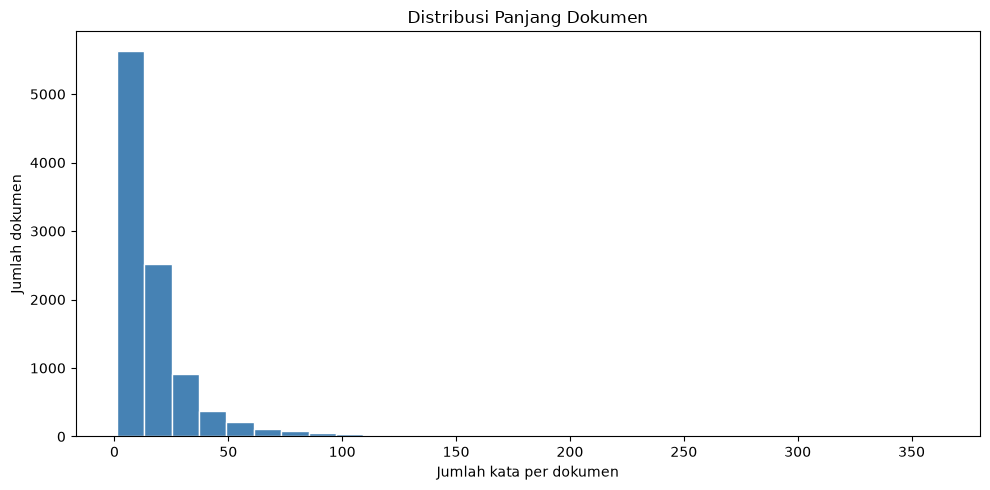

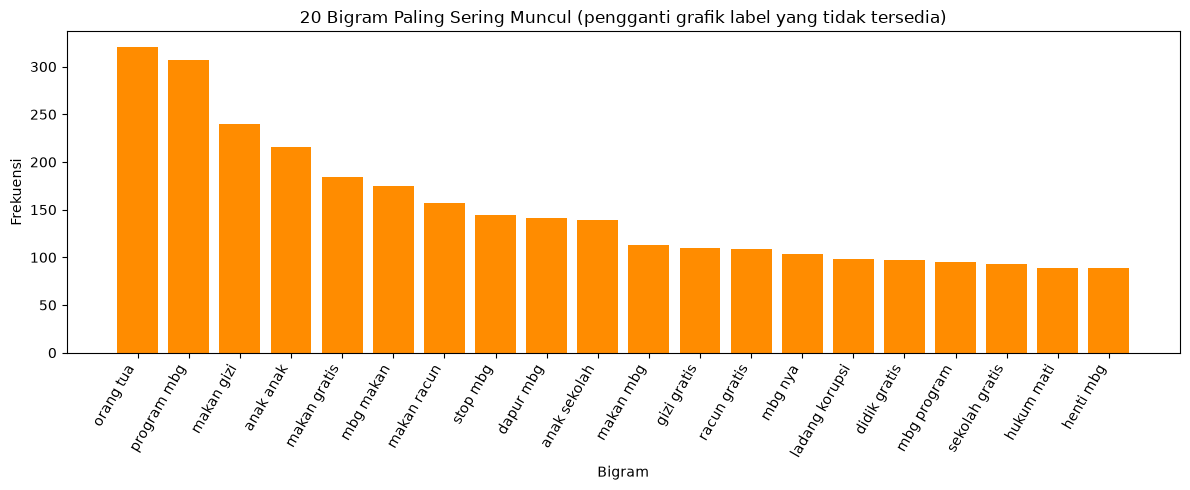

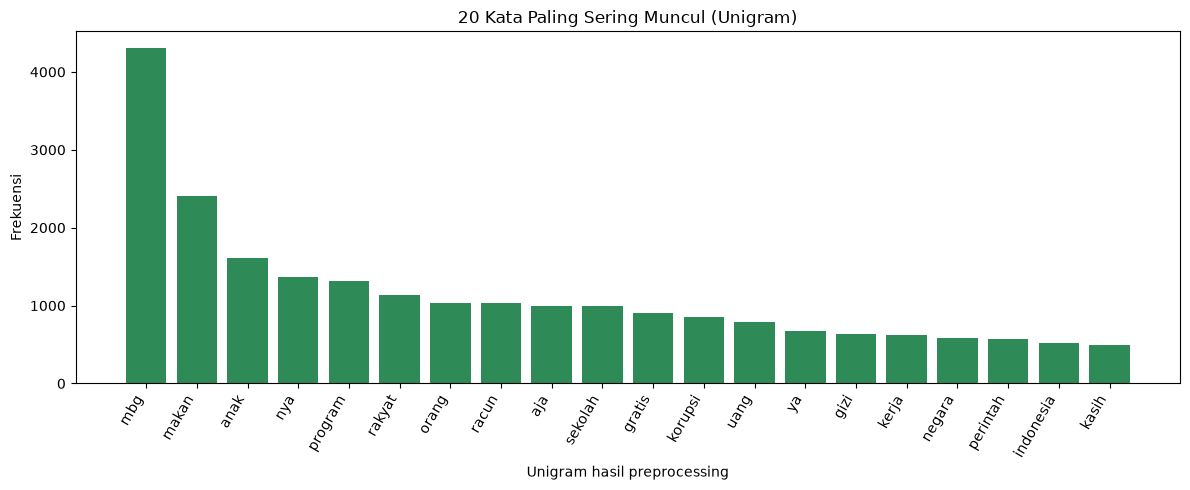

In [42]:
#visualisasi
# 1. Distribusi panjang dokumen (kata, teks asli)
plt.figure(figsize=(10, 5))
plt.hist(document_word_counts, bins=30, color="steelblue", edgecolor="white")
plt.xlabel("Jumlah kata per dokumen")
plt.ylabel("Jumlah dokumen")
plt.title("Distribusi Panjang Dokumen")
plt.tight_layout()
plt.show()

# 2. Distribusi label jika tersedia; jika tidak, top-20 bigram
if label_column:
    plt.figure(figsize=(10, 5))
    df[label_column].value_counts().plot(kind="bar", color="darkorange")
    plt.xlabel("Label")
    plt.ylabel("Jumlah dokumen")
    plt.title("Distribusi Label")
    plt.tight_layout()
    plt.show()
else:
    top_bigrams = bigram_frequency.most_common(20)
    plt.figure(figsize=(12, 5))
    plt.bar([" ".join(pair) for pair, _ in top_bigrams], [count for _, count in top_bigrams], color="darkorange")
    plt.xticks(rotation=60, ha="right")
    plt.xlabel("Bigram")
    plt.ylabel("Frekuensi")
    plt.title("20 Bigram Paling Sering Muncul (pengganti grafik label yang tidak tersedia)")
    plt.tight_layout()
    plt.show()

# 3. Frekuensi top-20 unigram
Top = unigram_frequency.most_common(20)
plt.figure(figsize=(12, 5))
plt.bar([word for word, _ in Top], [count for _, count in Top], color="seagreen")
plt.xticks(rotation=60, ha="right")
plt.xlabel("Unigram hasil preprocessing")
plt.ylabel("Frekuensi")
plt.title("20 Kata Paling Sering Muncul (Unigram)")
plt.tight_layout()
plt.show()

## 14. Analysis


In [43]:
#analysis 
possible_unigrams = vocab_size
possible_bigrams = vocab_size ** 2
possible_trigrams = vocab_size ** 3
analysis_table = pd.DataFrame([
    {"Model": "Unigram", "Konteks": "frekuensi token", "N-gram unik": len(unigram_frequency), "Kombinasi maksimum": possible_unigrams},
    {"Model": "Bigram", "Konteks": "1 kata sebelumnya", "N-gram unik": len(bigram_frequency), "Kombinasi maksimum": possible_bigrams},
    {"Model": "Trigram", "Konteks": "2 kata sebelumnya", "N-gram unik": len(trigram_frequency), "Kombinasi maksimum": possible_trigrams},
])
analysis_table["Coverage (%)"] = analysis_table.apply(
    lambda row: row["N-gram unik"] / row["Kombinasi maksimum"] * 100
    if row["Kombinasi maksimum"] else 0.0,
    axis=1,
)
display(analysis_table)

print("Keterbatasan dan catatan:")
print("- N-gram sparse: banyak kombinasi kata tidak terlihat dalam korpus.")
print("- Bigram/trigram hanya melihat konteks pendek dan tidak memahami semantik.")
print("- Stemming dan stopword removal dapat membuang informasi tertentu.")
print("- Kolom label tidak tersedia; evaluasi supervised tidak dilakukan.")
print("- POS/dependency merupakan prediksi Stanza dan tetap perlu ditinjau manual berdasarkan konteks.")

,Model,Konteks,N-gram unik,Kombinasi maksimum,Coverage (%)
0,Unigram,frekuensi token,11902,11902,100.000000
1,Bigram,1 kata sebelumnya,66906,141657604,0.047231
2,Trigram,2 kata sebelumnya,77852,1686008802808,0.000005


Keterbatasan dan catatan:
- N-gram sparse: banyak kombinasi kata tidak terlihat dalam korpus.
- Bigram/trigram hanya melihat konteks pendek dan tidak memahami semantik.
- Stemming dan stopword removal dapat membuang informasi tertentu.
- Kolom label tidak tersedia; evaluasi supervised tidak dilakukan.
- POS/dependency merupakan prediksi Stanza dan tetap perlu ditinjau manual berdasarkan konteks.


## 15. Conclusion

Notebook ini merangkum alur Praktikum 1-5: eksplorasi korpus, data cleaning, sentence segmentation, tokenization, normalization, stopword removal, stemming, POS tagging, dependency parsing, n-gram, language model, visualization, dan analysis.

Hasil POS/dependency adalah prediksi Stanza dan perlu ditinjau berdasarkan konteks, khususnya pada teks informal. Dataset tidak memiliki kolom label, sehingga distribusi label dan evaluasi klasifikasi supervised tidak tersedia.